# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Astrid Jimena Castuera Gómez
**Grupo:** 511  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler 
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")

In [7]:
display(df.head())
print("Dimensiones:", df.shape)
print("\nColumnas:", list(df.columns))
print("\nTipos de datos:")
print(df.dtypes)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones: (2427612, 20)

Columnas: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type             float64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_con

In [8]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
VendorID,2427612.0,1.888167,0.808684,1.000000,2.000000,2.000000,2.000000,7.000000
passenger_count,2415489.0,1.296144,1.881923,-5.000000,1.000000,1.000000,1.000000,100.000000
trip_distance,2415470.0,3.300702,5.167909,-99.987634,0.990000,1.700000,3.360000,1686.490000
RatecodeID,2415474.0,4.229419,17.202198,1.000000,1.000000,1.000000,1.000000,99.000000
PULocationID,2415487.0,164.139170,62.853858,1.000000,132.000000,161.000000,232.000000,265.000000
DOLocationID,2415475.0,163.223620,69.256125,1.000000,113.000000,162.000000,234.000000,265.000000
payment_type,2415487.0,1.174306,0.459415,1.000000,1.000000,1.000000,1.000000,4.000000
fare_amount,2415488.0,38.525671,542.376418,-1849.600000,9.300000,13.500000,21.900000,19995.589825
extra,2415487.0,1.567837,1.906552,-7.500000,0.000000,1.000000,2.500000,23.250000
mta_tax,2415462.0,0.484991,0.101868,-0.500000,0.500000,0.500000,0.500000,11.500000


In [9]:
print("\nValores de payment_type:")
print(df["payment_type"].value_counts(dropna=False))


Valores de payment_type:
payment_type
1.0    2051983
2.0     329533
4.0      23558
NaN      12125
3.0      10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [10]:
df_limpio = df.copy()
print("Dimensiones antes:", df_limpio.shape)
print("\nNulos por columna:")
print(df_limpio.isnull().sum())
print("\nDuplicados:", df_limpio.duplicated().sum())

df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

df_limpio = df_limpio[
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
].copy()

print("\nDimensiones después:", df_limpio.shape)

Dimensiones antes: (2427612, 20)

Nulos por columna:
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64

Duplicados: 11961

Dimensiones después: (2096600, 20)


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [11]:
df_cash = df_limpio[df_limpio["payment_type"] == 2].copy()
X = df_cash[[
    "trip_distance", 
    "trip_duration"]].copy()

print("Viajes en efectivo:", len(df_cash))
display(X.describe())

Viajes en efectivo: 282085


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,3.842165,17.507243
std,6.214391,40.684025
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
max,1686.490000,8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [12]:
X_log = np.log1p(X)

escalador = StandardScaler()
X_escalado = pd.DataFrame(escalador.fit_transform(X_log), columns=X.columns, index=X.index)

print("Variables con log1p:")
display(X_log.describe())
print("Variables estandarizadas:")
display(X_escalado.describe().round(4))

Variables con log1p:


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,1.225454,2.607608
std,0.763298,0.744450
min,0.009950,0.032790
25%,0.652325,2.128232
50%,0.993252,2.596498
75%,1.680828,3.085725
max,7.430997,9.032967


Variables estandarizadas:


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,0.0000,-0.0000
std,1.0000,1.0000
min,-1.5924,-3.4587
25%,-0.7509,-0.6439
50%,-0.3042,-0.0149
75%,0.5966,0.6422
max,8.1299,8.6310


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


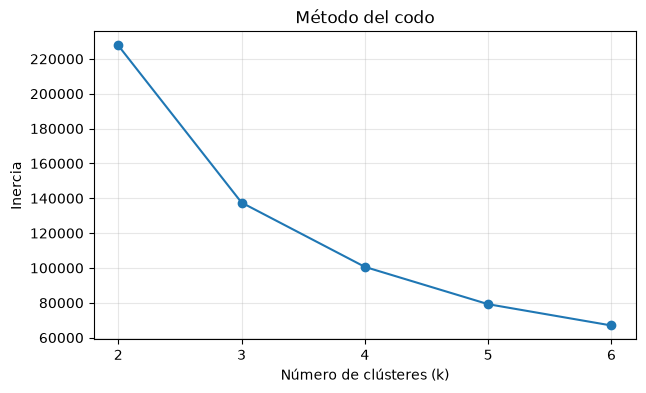

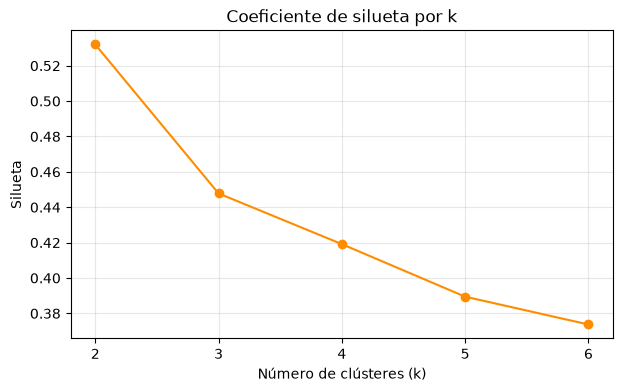

In [13]:
valores_k = [2, 3, 4, 5, 6]
inercias, siluetas = [], []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas, sample_size=5000, random_state=42))

tabla_k = pd.DataFrame({"k": valores_k, "Inercia": inercias, "Silueta": siluetas})
display(tabla_k.round(4))

plt.figure(figsize=(7, 4))
plt.plot(tabla_k["k"], tabla_k["Inercia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(tabla_k["k"], tabla_k["Silueta"], marker="o", color="darkorange")
plt.title("Coeficiente de silueta por k")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silueta")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

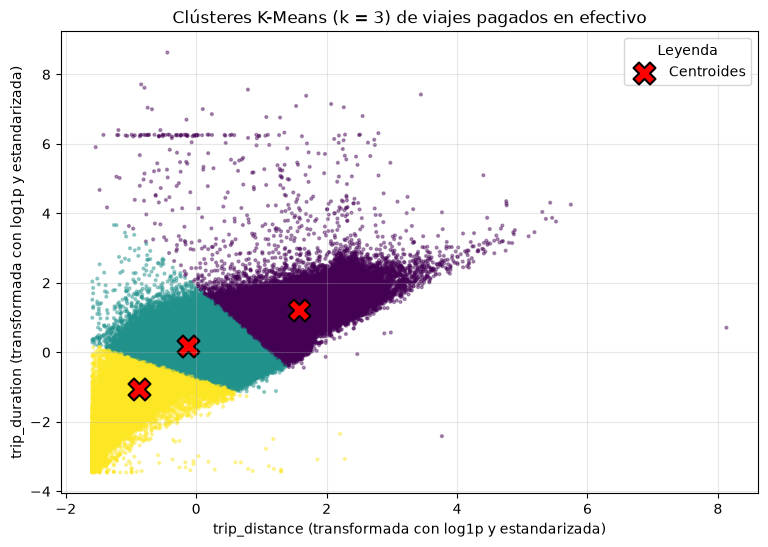

In [20]:
k_final = 3

modelo_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)

etiquetas = modelo_final.fit_predict(X_escalado)
centroides = modelo_final.cluster_centers_

plt.figure(figsize=(9, 6))
puntos = plt.scatter(X_escalado["trip_distance"], X_escalado["trip_duration"],
                     c=etiquetas, cmap="viridis", s=4, alpha=0.4)

plt.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=250, c="red",
            edgecolors="black", linewidths=1.5, label="Centroides")

plt.title("Clústeres K-Means (k = 3) de viajes pagados en efectivo")
plt.xlabel("trip_distance (transformada con log1p y estandarizada)")
plt.ylabel("trip_duration (transformada con log1p y estandarizada)")
plt.legend(title="Leyenda")
plt.grid(alpha=0.3)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [22]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

tabla_clusters = df_resultado.groupby("cluster").agg(
    viajes=("cluster", "size"),
    distancia_media=("trip_distance", "mean"),
    distancia_mediana=("trip_distance", "median"),
    duracion_media=("trip_duration", "mean"),
    duracion_mediana=("trip_duration", "median"),
).round(2)

display(tabla_clusters)

,viajes,distancia_media,distancia_mediana,duracion_media,duracion_mediana
cluster,,,,,
0,62395,11.55,9.81,39.48,31.40
1,125521,2.30,1.94,15.43,14.00
2,94169,0.80,0.76,5.72,5.82


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** <br>
Elegí k = 3. Para decidir comparé tres cosas: la inercia, la silueta y si los grupos tenían sentido. 
- Inercia: mide qué tan lejos están los viajes del centro de su grupo, y siempre baja cuando aumenta k. Lo importante es dónde deja de bajar tanto. Los valores para k = 2, 3, 4, 5 y 6 fueron: inercia (227,681 → 137,512 → 100,620 → 79,205 → 66,980). La mayor caída ocurre al pasar de k = 2 a k = 3 (de 227,681 a 137,512). A partir de k = 3 la curva empieza a estabilizarse: las mejoras son cada vez menores y ya no justifican agregar más grupos. Ese cambio de ritmo forma el codo, que se ve cerca de k = 3.
- Silueta: mide qué tan bien separados están los grupos, y mientras más alta, mejor. Los valores para k = 2, 3, 4, 5 y 6 fueron: silueta (0.53 → 0.45 → 0.42 → 0.39 → 0.37). El valor más alto es con k = 2, pero ese modelo solo divide los viajes en cortos y largos, y eso es poca información. Con k = 3 la silueta (0.45) sigue siendo aceptable, y desde k = 4 baja más, así que los grupos se encimarían.
- Claridad de los grupos: con k = 3 obtuve tres tipos de viaje fáciles de explicar: cortos (0.80 mi y 5.72 min en promedio), medios (2.30 mi y 15.43 min) y largos (11.55 mi y 39.48 min). En la gráfica se ven como tres zonas ordenadas de abajo a la izquierda hacia arriba a la derecha, cada una con su centroide.

Por lo tanto, k = 3 da una silueta razonable, aprovecha la mayor caída de inercia, es donde la curva empieza a estabilizarse y separa los viajes en grupos con diferencias claras que se pueden interpretar.


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:** <br>
- Clúster 0 — Viajes largos (62,395 viajes): es el grupo con menos viajes, pero con los recorridos más grandes. En promedio recorren 11.55 mi y duran 39.48 min, con medianas de 9.81 mi y 31.40 min. Aquí la media es bastante mayor que la mediana, porque hay viajes muy largos que jalan el promedio hacia arriba.
- Clúster 1 — Viajes medios (125,521 viajes): en promedio recorren 2.30 mi y duran 15.43 min, con medianas de 1.94 mi y 14.00 min. La media es un poco más alta que la mediana, lo que indica que algunos viajes un poco más largos suben el promedio. Son viajes urbanos típicos.
- Clúster 2 — Viajes cortos y rápidos (94,169 viajes): son los trayectos más cortos. En promedio recorren 0.80 mi y duran 5.72 min, y las medianas (0.76 mi y 5.82 min) son casi iguales a las medias. Eso indica que casi todos los viajes del grupo son parecidos entre sí. Son recorridos de pocas cuadras.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:** <br>
El clúster 0 (viajes largos) es el que tiene la mayor duración promedio: 39.48 min. Comparándolo con los otros grupos de la tabla, el clúster 1 tiene 15.43 min y el clúster 2 tiene 5.72 min.
Este mismo clúster también tiene la mayor distancia promedio: 11.55 mi, frente a 2.30 mi del clúster 1 y 0.80 mi del clúster 2. Es decir, el grupo que más dura es también el que más recorre.
Esto tiene sentido porque, en general, un viaje más largo en distancia necesita más tiempo. Se ve en toda la tabla: al pasar del clúster 2 al 1 y al 0, tanto la distancia como la duración aumentan juntas.
Además, en este grupo la media es mayor que la mediana en las dos variables (39.48 vs 31.40 min y 11.55 vs 9.81 mi). Eso indica que algunos viajes muy largos suben el promedio, así que un viaje típico del grupo es un poco más corto que lo que muestran las medias, pero sigue siendo el más largo de los tres grupos.


**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo? 

**Respuesta:**<br>
El grupo más numeroso es el clúster 1 (viajes medios), con 125,521 viajes (cerca del 45% del total). En él predominan distancias de alrededor de 2 mi (mediana 1.94) y duraciones de alrededor de 14 min, es decir, el viaje urbano típico en efectivo.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**